# AIML Lab Exercise 8: (i) Random Forest and (ii) Boosting Ensemble Methods
**Dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset (breast_cancer.csv)

**Ensemble methods** combine many weak models (here, decision trees) into one strong model.
- **Part (i) – Random Forest (Bagging):** many deep trees are trained *in parallel* on bootstrap samples with random feature subsets, and their predictions are combined by **majority voting**. This mainly reduces **variance**.
- **Part (ii) – Boosting (AdaBoost and Gradient Boosting):** shallow trees are trained *sequentially*, each one focusing on the mistakes of the previous ones. This mainly reduces **bias**.

The task is to classify a tumour as **malignant** or **benign** from 30 numeric features computed from a cell image.

## 1. Import the required libraries

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)

warnings.filterwarnings('ignore', message='X does not have valid feature names')
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset and display basic information

Dataset loaded successfully! Shape: (569, 31)
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant



Class distribution:
 diagnosis
benign       357
malignant    212
Name: count, dtype: int64


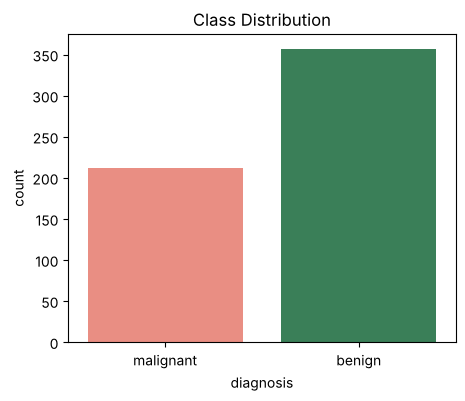

In [2]:
df = pd.read_csv('breast_cancer.csv')
print("Dataset loaded successfully! Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df.head())
print("\nClass distribution:\n", df['diagnosis'].value_counts())

plt.figure(figsize=(5, 4))
sns.countplot(x=df['diagnosis'], hue=df['diagnosis'], palette=['salmon', 'seagreen'], legend=False)
plt.title('Class Distribution')
plt.show()

## 3. Prepare the data and split into training and testing sets
**Malignant** is encoded as **1** (the positive class we want to detect) and **benign** as **0**. Tree-based models do not need feature scaling.

In [3]:
X = df.drop(columns='diagnosis')
y = (df['diagnosis'] == 'malignant').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set:", X_train.shape, " Testing set:", X_test.shape)

Training set:

 (455, 30)  Testing set: (114, 30)


## 4. Baseline: a single decision tree

In [4]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
print("Decision tree - training accuracy:", round(tree.score(X_train, y_train), 4))
print("Decision tree - test accuracy    :", round(tree.score(X_test, y_test), 4))

Decision tree - training accuracy: 1.0
Decision tree - test accuracy    : 0.9298


**Interpretation:** A fully grown tree fits the training data perfectly (100%) but scores lower on the test set — it **overfits** (high variance). Ensembles fix this.

---
# Part (i): Random Forest
**Algorithm:**
1. Draw a **bootstrap sample** (random sampling with replacement) from the training set.
2. Grow a decision tree on it; at each split consider only a **random subset of √(n_features)** features.
3. Repeat to build *N* trees.
4. Predict by **majority vote** of all trees.

## 5. Random forest from scratch (to understand the idea)

In [5]:
class SimpleRandomForest:
    def __init__(self, n_trees=50, seed=42):
        self.n_trees = n_trees
        self.rng = np.random.default_rng(seed)
        self.trees = []

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        for _ in range(self.n_trees):
            idx = self.rng.integers(0, len(X), len(X))                      # bootstrap sample
            t = DecisionTreeClassifier(max_features='sqrt', random_state=int(self.rng.integers(1e6)))
            self.trees.append(t.fit(X[idx], y[idx]))
        return self

    def predict(self, X):
        votes = np.array([t.predict(np.asarray(X)) for t in self.trees])    # shape: (n_trees, n_samples)
        return (votes.mean(axis=0) >= 0.5).astype(int)                       # majority vote

simple_rf = SimpleRandomForest(n_trees=50).fit(X_train, y_train)
print("Random forest from scratch - test accuracy:", round(accuracy_score(y_test, simple_rf.predict(X_test)), 4))

Random forest from scratch - test accuracy: 0.9649


## 6. Random forest using scikit-learn
The **Out-of-Bag (OOB) score** evaluates each tree on the training samples that were *not* in its bootstrap sample, giving a free estimate of test accuracy.

In [6]:
rf = RandomForestClassifier(n_estimators=200, max_features='sqrt', oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random forest - training accuracy:", round(rf.score(X_train, y_train), 4))
print("Random forest - OOB score        :", round(rf.oob_score_, 4))
print("Random forest - test accuracy    :", round(accuracy_score(y_test, rf_pred), 4))

Random forest - training accuracy: 1.0
Random forest - OOB score        : 0.9538
Random forest - test accuracy    : 0.9649


## 7. Evaluate the random forest: confusion matrix and classification report

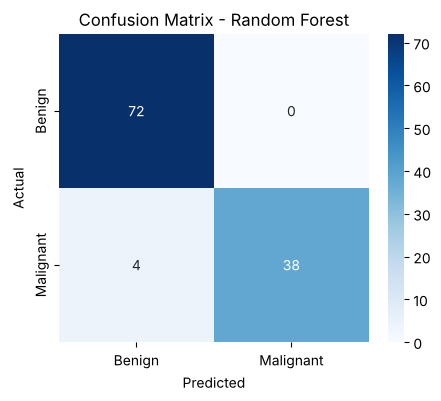

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



In [7]:
def show_confusion(y_true, y_pred, title):
    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.show()

show_confusion(y_test, rf_pred, 'Confusion Matrix - Random Forest')
print(classification_report(y_test, rf_pred, target_names=['Benign', 'Malignant']))

## 8. Feature importance
Random forests measure how much each feature reduces impurity, averaged over all trees.

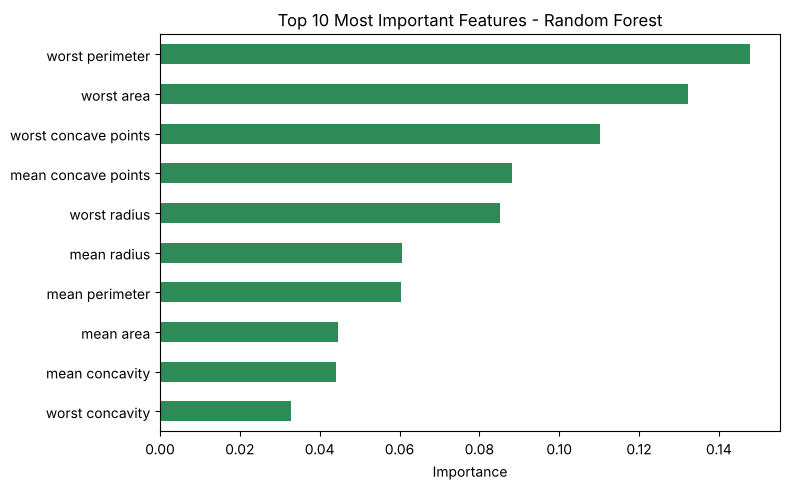

In [8]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
importances.head(10)[::-1].plot.barh(color='seagreen')
plt.xlabel('Importance')
plt.title('Top 10 Most Important Features - Random Forest')
plt.tight_layout()
plt.show()

## 9. Effect of the number of trees

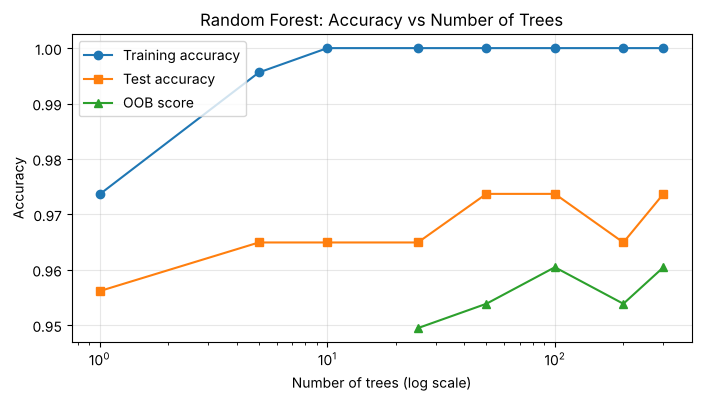

In [9]:
n_trees_list = [1, 5, 10, 25, 50, 100, 200, 300]
train_acc, test_acc, oob = [], [], []
for n in n_trees_list:
    m = RandomForestClassifier(n_estimators=n, oob_score=n >= 25, random_state=42, n_jobs=-1).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))
    oob.append(m.oob_score_ if n >= 25 else np.nan)

plt.figure(figsize=(8, 4))
plt.plot(n_trees_list, train_acc, 'o-', label='Training accuracy')
plt.plot(n_trees_list, test_acc, 's-', label='Test accuracy')
plt.plot(n_trees_list, oob, '^-', label='OOB score')
plt.xscale('log')
plt.xlabel('Number of trees (log scale)')
plt.ylabel('Accuracy')
plt.title('Random Forest: Accuracy vs Number of Trees')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretation:** Accuracy improves quickly as trees are added and then levels off. Adding more trees does not cause overfitting — it only increases computation time.

---
# Part (ii): Boosting
**AdaBoost (Adaptive Boosting):**
1. Give every training sample an equal weight.
2. Train a weak learner (a **decision stump** — a tree of depth 1).
3. Compute its weighted error ε and its vote weight α = ½ ln((1 − ε)/ε).
4. **Increase the weights of misclassified samples** so the next learner focuses on them.
5. Final prediction = sign of the weighted vote Σ αₜ hₜ(x).

**Gradient Boosting:** each new tree is fitted to the **residual errors (negative gradient of the loss)** of the current ensemble, and added with a small learning rate.

## 10. AdaBoost from scratch (to understand the idea)

In [10]:
class SimpleAdaBoost:
    def __init__(self, n_rounds=50):
        self.n_rounds = n_rounds
        self.stumps, self.alphas = [], []

    def fit(self, X, y):
        X, y = np.asarray(X), np.where(np.asarray(y) == 1, 1, -1)    # labels must be -1 / +1
        w = np.full(len(y), 1 / len(y))                                # equal initial weights
        for _ in range(self.n_rounds):
            stump = DecisionTreeClassifier(max_depth=1).fit(X, y, sample_weight=w)
            pred = stump.predict(X)
            err = np.clip(w[pred != y].sum(), 1e-10, 1 - 1e-10)
            alpha = 0.5 * np.log((1 - err) / err)
            w *= np.exp(-alpha * y * pred)                             # boost misclassified samples
            w /= w.sum()
            self.stumps.append(stump)
            self.alphas.append(alpha)
        return self

    def predict(self, X):
        score = sum(a * s.predict(np.asarray(X)) for a, s in zip(self.alphas, self.stumps))
        return (score > 0).astype(int)

simple_ada = SimpleAdaBoost(n_rounds=50).fit(X_train, y_train)
print("AdaBoost from scratch - test accuracy:", round(accuracy_score(y_test, simple_ada.predict(X_test)), 4))
print("Vote weights (alpha) of the first 5 stumps:", np.round(simple_ada.alphas[:5], 3))

AdaBoost from scratch - test accuracy: 0.9825
Vote weights (alpha) of the first 5 stumps: [1.291 0.836 0.768 0.585 0.605]


## 11. AdaBoost using scikit-learn

AdaBoost - training accuracy: 1.0
AdaBoost - test accuracy    : 0.9737


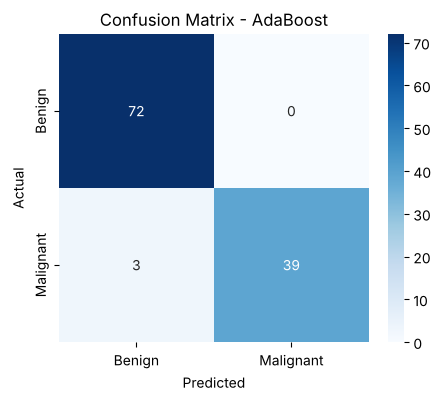

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [11]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200,
                         learning_rate=0.5, random_state=42)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

print("AdaBoost - training accuracy:", round(ada.score(X_train, y_train), 4))
print("AdaBoost - test accuracy    :", round(accuracy_score(y_test, ada_pred), 4))
show_confusion(y_test, ada_pred, 'Confusion Matrix - AdaBoost')
print(classification_report(y_test, ada_pred, target_names=['Benign', 'Malignant']))

## 12. Gradient Boosting using scikit-learn

Gradient Boosting - training accuracy: 1.0
Gradient Boosting - test accuracy    : 0.9649


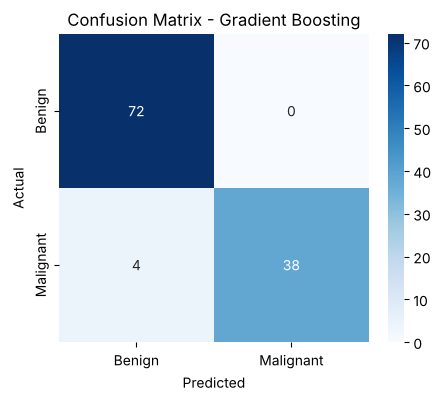

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



In [12]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

print("Gradient Boosting - training accuracy:", round(gb.score(X_train, y_train), 4))
print("Gradient Boosting - test accuracy    :", round(accuracy_score(y_test, gb_pred), 4))
show_confusion(y_test, gb_pred, 'Confusion Matrix - Gradient Boosting')
print(classification_report(y_test, gb_pred, target_names=['Benign', 'Malignant']))

## 13. Test accuracy vs number of boosting rounds
`staged_predict` gives the prediction of the ensemble after each boosting round.

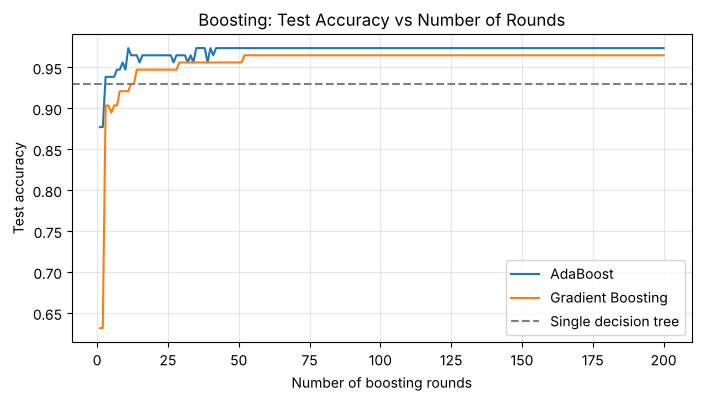

In [13]:
ada_staged = [accuracy_score(y_test, p) for p in ada.staged_predict(X_test)]
gb_staged = [accuracy_score(y_test, p) for p in gb.staged_predict(X_test)]

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(ada_staged) + 1), ada_staged, label='AdaBoost')
plt.plot(range(1, len(gb_staged) + 1), gb_staged, label='Gradient Boosting')
plt.axhline(tree.score(X_test, y_test), color='gray', linestyle='--', label='Single decision tree')
plt.xlabel('Number of boosting rounds')
plt.ylabel('Test accuracy')
plt.title('Boosting: Test Accuracy vs Number of Rounds')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 14. Compare all models (test metrics and 5-fold cross-validation)

,Accuracy,Precision,Recall,F1-score,ROC AUC,CV accuracy (mean)
Model,,,,,,
Decision Tree,0.9298,0.9048,0.9048,0.9048,0.9246,0.9104
Random Forest,0.9649,1.0000,0.9048,0.9500,0.9942,0.9543
AdaBoost,0.9737,1.0000,0.9286,0.9630,0.9861,0.9613
Gradient Boosting,0.9649,1.0000,0.9048,0.9500,0.9954,0.9544


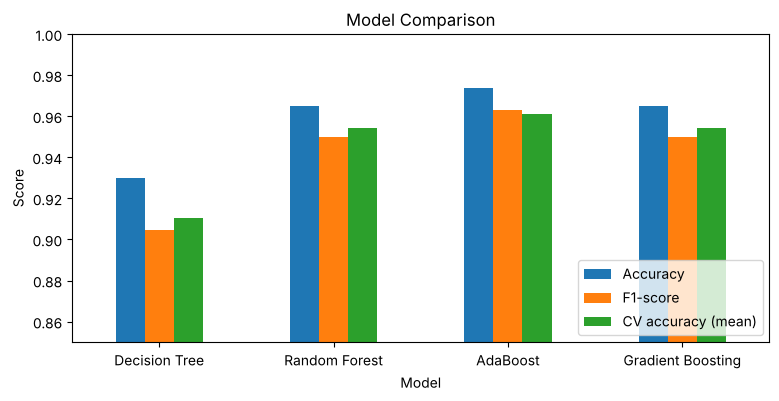

In [14]:
models = {
    'Decision Tree': tree,
    'Random Forest': rf,
    'AdaBoost': ada,
    'Gradient Boosting': gb,
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1-score': f1_score(y_test, pred),
                 'ROC AUC': roc_auc_score(y_test, prob),
                 'CV accuracy (mean)': cross_val_score(model, X, y, cv=cv).mean()})
results = pd.DataFrame(rows).set_index('Model').round(4)
display(results)

results[['Accuracy', 'F1-score', 'CV accuracy (mean)']].plot.bar(figsize=(9, 4), rot=0)
plt.ylim(0.85, 1.0)
plt.ylabel('Score')
plt.title('Model Comparison')
plt.legend(loc='lower right')
plt.show()

## 15. ROC curves of all models

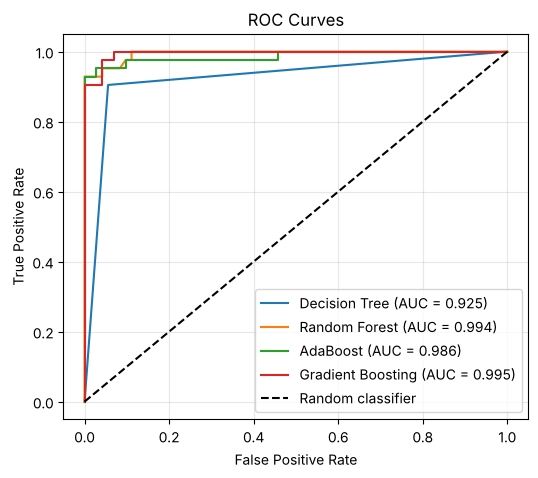

In [15]:
plt.figure(figsize=(6, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'ROC AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretation:** All three ensembles beat the single decision tree on accuracy, F1-score, cross-validated accuracy and AUC. Bagging (random forest) reduces the variance of deep trees, while boosting builds a strong model from many weak, shallow learners.

| | Bagging / Random Forest | Boosting |
|---|---|---|
| Training | Parallel, independent trees | Sequential, each tree corrects the previous |
| Base learner | Deep (low-bias, high-variance) trees | Shallow (high-bias, low-variance) trees |
| Mainly reduces | Variance | Bias |
| Sample weighting | Bootstrap sampling, equal weights | Misclassified samples get higher weights (AdaBoost) / fit residuals (GB) |
| Overfitting risk | Low | Higher if too many rounds or a high learning rate |

## 16. Documentation summary
1. Loaded the breast cancer dataset, checked for missing values and the class distribution
2. Encoded the target and split the data into training and testing sets
3. Trained a single decision tree as a baseline (overfits)
4. **Random Forest:** implemented a simple random forest from scratch, trained scikit-learn's `RandomForestClassifier`, reported OOB score, confusion matrix, classification report and feature importance, and studied the effect of the number of trees
5. **Boosting:** implemented AdaBoost from scratch, trained scikit-learn's `AdaBoostClassifier` and `GradientBoostingClassifier`, and plotted test accuracy vs number of boosting rounds
6. Compared all models using accuracy, precision, recall, F1-score, ROC AUC and 5-fold cross-validation, and plotted their ROC curves

**Result:** Random forest and boosting ensembles were implemented successfully and both outperform a single decision tree on the breast cancer dataset.